In [15]:
import torch
import matplotlib.pyplot as plt
import os
import numpy as np
import pandas as pd

In [87]:
test_results = pd.read_csv('test.csv', dtype=str)
# to dataframe
test_results = pd.DataFrame(test_results)
# Strip any leading or trailing spaces from the column names
test_results.columns = test_results.columns.str.strip()
test_results = test_results.apply(lambda x: x.str.strip() if x.dtype == "object" else x)

for i in range(len(test_results)):
    seeds = test_results.iloc[i]['seed'].split(' ')
    dataset = test_results.iloc[i]['dataset']
    usage = test_results.iloc[i]['usage']
    model = test_results.iloc[i]['model']
    lr = test_results.iloc[i]['lr']
    snr = test_results.iloc[i]['snr']
    snvr = test_results.iloc[i]['snvr']
    
    # express lr, snr and snvr in scientific notation 1e-4
    ckpt_path = f'./test_ckpt/{dataset}_{usage}_{model}_{lr}_{snr}_{snvr}.pth'
    if not os.path.exists(ckpt_path):
        continue
    ckpt = torch.load(ckpt_path)
    
    best_valid_acc = []
    best_test_acc = []
    for seed in seeds:
        seed = int(seed)
        best_valid_acc.append(ckpt[seed]['best_epoch']['valid_acc'])
        best_test_acc.append(ckpt[seed]['best_epoch']['test_acc'])
    
    test_results.at[i, 'best_valid_acc'] = np.mean(best_valid_acc).round(4)
    test_results.at[i, 'best_test_acc'] = np.mean(best_test_acc).round(4)
    
print(test_results.drop(columns=['seed','weight_decay','warm_up','batch_size']).to_string(index=False))

 dataset usage             model   lr  snr snvr epochs  best_valid_acc  best_test_acc
imagenet  0.05 convnext-tiny-0.5 4e-3  0.0  0.0    200          0.2149         0.1997
imagenet  0.05 convnext-tiny-0.5 4e-3 1e-5  0.0    200          0.2235         0.2050
imagenet  0.05 convnext-tiny-0.5 4e-3 1e-6  0.0    200          0.2222         0.2034
imagenet  0.05 convnext-tiny-0.5 4e-3 1e-7  0.0    200          0.2227         0.2050
imagenet  0.05 convnext-tiny-0.5 4e-3 1e-5 1e-1    200          0.2354         0.2167
imagenet  0.05 convnext-tiny-0.5 1e-3  0.0  0.0    200          0.2250         0.2057
imagenet  0.05 convnext-tiny-0.5 1e-3 1e-5  0.0    200          0.2259         0.2035
imagenet  0.05 convnext-tiny-0.5 1e-3 1e-6  0.0    200             NaN            NaN
imagenet  0.05 convnext-tiny-0.5 1e-3 1e-5 1e-1    200             NaN            NaN
imagenet   0.1 convnext-tiny-0.5 4e-3  0.0  0.0    200          0.3491         0.3238
imagenet   0.1 convnext-tiny-0.5 4e-3 1e-5  0.0    200

In [56]:
ckpt_path = 'test_ckpt/imagenet_0.05_convnext-tiny-0.5_1e-3_0.0_0.0.pth'
ckpt = torch.load(ckpt_path)
for i, acc in enumerate(ckpt[42]['valid_acc']):
    print(i, acc)

0 0.0055416796753044026
1 0.009288167343115829
2 0.01123946300343428
3 0.018029971901342493
4 0.02411801436153606
5 0.03496721823290665
6 0.04300655635341867
7 0.051280049953168906
8 0.062363409303777706
9 0.07727130814861068
10 0.09233531064626913
11 0.1035747736497034
12 0.11130190446456448
13 0.1277708398376522
14 0.1372151108335935
15 0.14673743365594755
16 0.16250390259132064
17 0.1644551982516391
18 0.17233843271932564
19 0.1809241336247268
20 0.18646581330003123
21 0.18982204183577897
22 0.18958788635654075
23 0.1925538557602248
24 0.19075866375273182
25 0.1963003434280362
26 0.1954417733374961
27 0.18982204183577897
28 0.19349047767717764
29 0.18841710896034966
30 0.18709022791133312
31 0.18755853886980955
32 0.18818295348111147
33 0.188026849828286
34 0.1878707461754605
35 0.19075866375273182
36 0.19005619731501716
37 0.18794879800187325
38 0.19458320324695597
39 0.1917733374960974
40 0.19060256009990634
41 0.18709022791133312
42 0.19083671557914456
43 0.1896659381829535
44 0.

ConvNeXt(
  (features): Sequential(
    (0): Conv2dNormActivation(
      (0): Conv2d(3, 48, kernel_size=(4, 4), stride=(4, 4))
      (1): LayerNorm2d((48,), eps=1e-06, elementwise_affine=True)
    )
    (1): Sequential(
      (0): CNBlock(
        (block): Sequential(
          (0): Conv2d(48, 48, kernel_size=(7, 7), stride=(1, 1), padding=(3, 3), groups=48)
          (1): Permute()
          (2): LayerNorm((48,), eps=1e-06, elementwise_affine=True)
          (3): Linear(in_features=48, out_features=192, bias=True)
          (4): GELU(approximate='none')
          (5): Linear(in_features=192, out_features=48, bias=True)
          (6): Permute()
        )
        (stochastic_depth): StochasticDepth(p=0.0, mode=row)
      )
      (1): CNBlock(
        (block): Sequential(
          (0): Conv2d(48, 48, kernel_size=(7, 7), stride=(1, 1), padding=(3, 3), groups=48)
          (1): Permute()
          (2): LayerNorm((48,), eps=1e-06, elementwise_affine=True)
          (3): Linear(in_features=

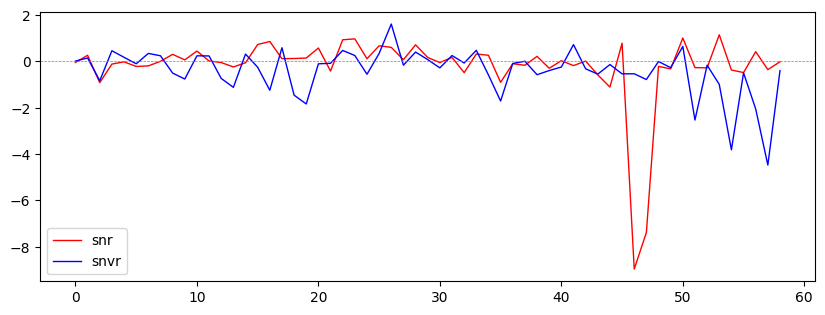

In [88]:
from torchvision.models.convnext import CNBlockConfig, _convnext

def calc_sn_uv(weight, n_power=5, eps=1e-12):
    weight_mat = weight

    height = weight_mat.size(0)
    weight_mat = weight_mat.view(height, -1)

    u = torch.randn(1, weight_mat.shape[0])  # move u to GPU
    for _ in range(n_power):
        v = torch.mm(u, weight_mat)  # [1, n]
        v = v / (torch.norm(v) + eps)
        u = torch.mm(v, weight_mat.T)  # [1, m]
        u = u / (torch.norm(u) + eps)

    sn = (torch.mul(torch.ones(1, weight_mat.shape[0]), torch.sum(torch.mm(torch.mm(u, weight_mat), v.T)))).T
    uv = torch.mm(u.T, v)

    return sn, uv

model_dict = {
    'baseline':'test_ckpt/imagenet_0.1_convnext-tiny-0.5_4e-3_0.0_0.0_model.pth',
    'snr':'test_ckpt/imagenet_0.1_convnext-tiny-0.5_4e-3_1e-5_0.0_model.pth',
    'snvr':'test_ckpt/imagenet_0.1_convnext-tiny-0.5_4e-3_1e-5_1e-1_model.pth',
}

block_setting = [
    CNBlockConfig(48, 96, 3),
    CNBlockConfig(96, 192, 3),
    CNBlockConfig(192, 384, 9),
    CNBlockConfig(384, None, 3),
]
model = _convnext(block_setting, 0.1, None, True, num_classes=1000)
print(model)
# for name, path in model_dict.items():
#     plt.figure(figsize=(10, 2))
#     s_list = []
#     model.load_state_dict(torch.load(path))
#     for param in model.parameters():
#         if param.dim() < 2:
#             continue
#         if param.size(0) == 1 or param.view(param.size(0), -1).size(1) == 1:
#             continue
#         s = np.linalg.svd(param.view(param.size(0), -1).detach().cpu().numpy(), compute_uv=False)
#         s_list.append(s.reshape(-1))
#     for i, s in enumerate(s_list):
#         plt.scatter([i]*len(s), s, alpha=0.5, c='black', s=4)
#     plt.plot(list(np.max(x) for x in s_list), c='red', lw=1)
#     # plt.plot(list(np.mean(x) for x in s_list), c='blue', lw=1)
#     for y in range(0, 110, 20):
#         plt.axhline(y, c='gray', lw=0.5, ls='--')
#     plt.ylim(0, 110)
#     plt.show()

labels = ['baseline', 'snr', 'snvr']
baseline = []
snr = []
snvr = []
plt.figure(figsize=(10, 3.5))
for i, (name, path) in enumerate(model_dict.items()):
    s_list = []
    model.load_state_dict(torch.load(path))
    for param in model.parameters():
        if param.dim() < 2:
            continue
        if param.size(0) == 1 or param.view(param.size(0), -1).size(1) == 1:
            continue
        s = np.linalg.svd(param.view(param.size(0), -1).detach().cpu().numpy(), compute_uv=False)
        s_list.append(s.reshape(-1))
    if i == 0:
        baseline.extend(list(np.median(x) for x in s_list))
    if i == 1:
        snr.extend(list(np.median(x) for x in s_list))
    if i == 2:
        snvr.extend(list(np.median(x) for x in s_list))

baseline = np.array(baseline)
snr = np.array(snr)
snvr = np.array(snvr)

plt.plot(snr - baseline, c='red', lw=1, label='snr')
plt.plot(snvr - baseline, c='blue', lw=1, label='snvr')
plt.axhline(0, c='gray', lw=0.5, ls='--')
plt.legend()
plt.show()
